In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage

In [2]:
# 1. Create a full DataFrame with multiple attributes
data = {
    'Flavor': ['Vanilla', 'Chocolate', 'Strawberry', 'Lemon Sorbet', 'Mint Choc Chip'],
    'Sweetness': [8, 9, 7, 3, 8],
    'Creaminess': [9, 9, 8, 2, 8],
    'Price_INR': [120, 140, 130, 90, 150] # Extra feature we won't cluster by
}

df = pd.DataFrame(data)
print("--- Full DataFrame ---")
print(df)

--- Full DataFrame ---
           Flavor  Sweetness  Creaminess  Price_INR
0         Vanilla          8           9        120
1       Chocolate          9           9        140
2      Strawberry          7           8        130
3    Lemon Sorbet          3           2         90
4  Mint Choc Chip          8           8        150


In [12]:
features = df[['Sweetness', 'Creaminess']]
print("---Features for Clustering---")
print(features)

linked = linkage(features, method='ward')
# print(linked)
from scipy.cluster.hierarchy import cophenet
from scipy.spatial.distance import pdist

c, coph_dists = cophenet(linked, pdist(features))
print("Cophenetic Correlation Coefficient:", c)
print(f"contains the cophenetic distances: ", coph_dists)

# Cophenetic Distance:
# It is the distance (height in the dendrogram) at which two original observations are first merged into the same cluster.

---Features for Clustering---
   Sweetness  Creaminess
0          8           9
1          9           9
2          7           8
3          3           2
4          8           8
Cophenetic Correlation Coefficient: 0.9860390726373361
contains the cophenetic distances:  [ 1.          2.         10.37304198  2.          2.         10.37304198
  2.         10.37304198  1.         10.37304198]


| Column | Meaning                                            |
| ------ | -------------------------------------------------- |
| 1      | First cluster/data point being merged              |
| 2      | Second cluster/data point being merged             |
| 3      | Distance or Ward merging cost                      |
| 4      | Number of original observations in the new cluster |


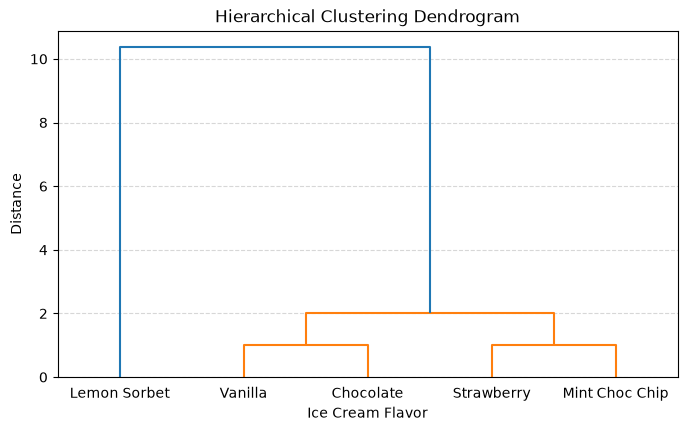

In [4]:
plt.figure(figsize=(8, 4.5))
dendrogram(linked,
           labels=df['Flavor'].values,
           leaf_rotation=0,
           leaf_font_size=10)
plt.title('Hierarchical Clustering Dendrogram')
plt.xlabel('Ice Cream Flavor')
plt.ylabel('Distance')
plt.grid(axis='y',linestyle='--',alpha=0.5)
plt.show()